In [1]:

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import re
import pickle
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F

pd.set_option('display.max_colwidth', None)
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


# Knowing the problem 

Smart MCQ Solver Challenge
Build AI systems that solve & predict top 3 correct answers for challenging multiple choice questions

- we are given prompts and 5 options our model should predict answers in top -3 fashion 

# Import datasets

In [2]:
train = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")
df = train.copy()
print(train.shape)
print(test.shape)

(2000, 8)
(500, 7)


# Setup HuggingFace and WandB Tokens

In [3]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("HF_TOKEN")
secret_value_1 = user_secrets.get_secret("WANDB_API_KEY")


In [4]:
import wandb


os.environ["WANDB_ENTITY"] = "23f3003322-indian-institute-of-technology-madras"
os.environ["WANDB_PROJECT"] = "23f3003322-t22026"

wandb.login(key=secret_value_1)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


True

# Basic EDA 

Lets start with looking into the data

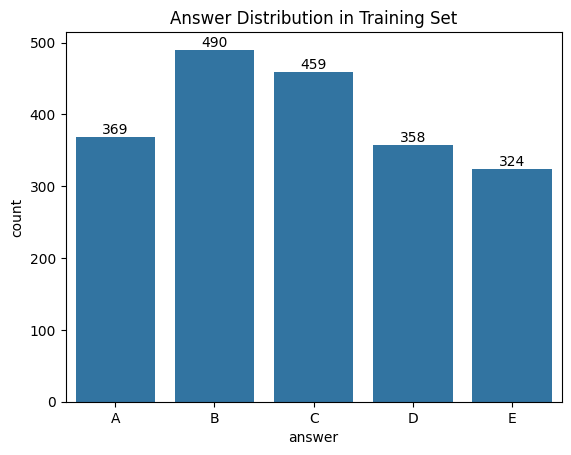

answer
A    0.1845
B    0.2450
C    0.2295
D    0.1790
E    0.1620
Name: proportion, dtype: float64


In [5]:
ax = sns.countplot(data=df, x='answer', order=['A','B','C','D','E'])
ax.bar_label(ax.containers[0])
plt.title("Answer Distribution in Training Set")
plt.show()

# Proportion
print(df['answer'].value_counts(normalize=True).sort_index())

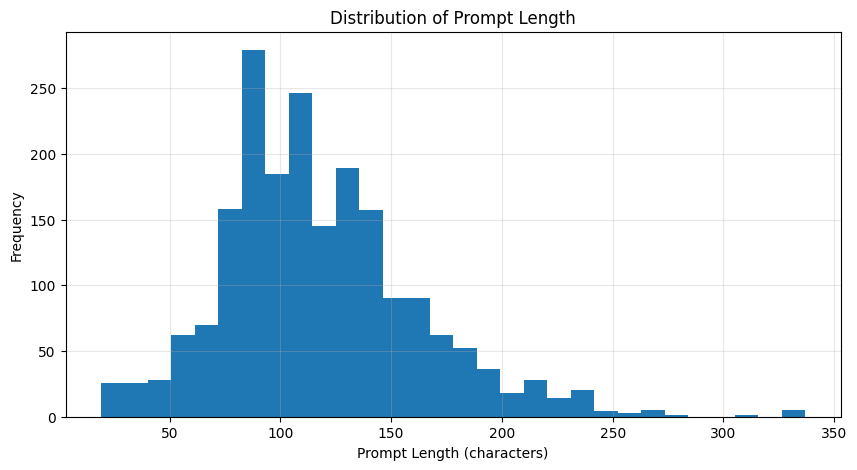

In [6]:
df["prompt_len"] = df["prompt"].str.len()

df["prompt_len"].describe()

plt.figure(figsize=(10, 5))
plt.hist(df["prompt_len"], bins=30)

plt.title("Distribution of Prompt Length")
plt.xlabel("Prompt Length (characters)")
plt.ylabel("Frequency")

plt.grid(alpha=0.3)
plt.show()

lets look into the prompts

In [7]:
df[df["prompt"].duplicated()]

,id,prompt,A,B,C,D,E,answer,prompt_len
112,113,Select the most accurate option: What are the constituents of cold dark matter?,"They are unknown, but possibilities include large objects like MACHOs or new particles such as WIMPs and axions.",They are known to be black holes and Preon stars.,They are only MACHOs.,They are clusters of brown dwarfs.,They are new particles such as RAMBOs.,A,79
120,121,Pick the best possible answer: What is the metallicity of Kapteyn's star estimated to be?,8 times more than the Sun,8 times less than the Sun,13 light years away from Earth,Unknown,Equal to the Sun,B,89
209,210,Select the most accurate option: What is the reason behind the largest externally observed electrical effects when two conductors are separated by the smallest distance without touching? based on the given context.,"The surface charge on a conductor depends on the magnitude of the electric field, which in turn depends on the temperature between the surfaces.","The surface charge on a conductor depends on the magnitude of the magnetic field, which in turn depends on the distance between the surfaces.","The surface charge on a conductor depends on the magnitude of the electric field, which in turn depends on the angle between the surfaces.","The surface charge on a conductor depends on the magnitude of the electric field, which in turn depends on the distance between the surfaces.","The surface charge on a conductor depends on the magnitude of the electric field, which in turn depends on the pressure between the surfaces.",D,214
238,239,Choose the correct answer: What is water hammer? based on the given context.,Water hammer is a type of water turbine used in hydroelectric generating stations to generate electricity.,Water hammer is a type of air trap or standpipe used to dampen the sound of moving water in plumbing frameworks.,Water hammer is a type of plumbing tool used to break pipelines and absorb the potentially damaging forces caused by moving water.,Water hammer is a type of water pump used to boost the pressure of water in pipelines.,"Water hammer is a loud banging noise resembling a hammering sound that occurs when moving water is suddenly stopped, causing a rise in pressure and resulting shock wave.",E,76
258,259,Identify the correct statement: What is the effect generated by a spinning superconductor? among the listed options.,"An electric field, precisely aligned with the spin axis.","A magnetic field, randomly aligned with the spin axis.","A magnetic field, precisely aligned with the spin axis.","A gravitational field, randomly aligned with the spin axis.","A gravitational field, precisely aligned with the spin axis.",C,116
...,...,...,...,...,...,...,...,...,...
1973,1974,Determine the correct option: What is reciprocal length or inverse length? carefully.,"Reciprocal length or inverse length is a quantity or measurement used in physics and chemistry. It is the reciprocal of time, and common units used for this measurement include the reciprocal second or inverse second (symbol: s−1), the reciprocal minute or inverse minute (symbol: min−1).","Reciprocal length or inverse length is a quantity or measurement used in geography and geology. It is the reciprocal of area, and common units used for this measurement include the reciprocal square metre or inverse square metre (symbol: m−2), the reciprocal square kilometre or inverse square kilometre (symbol: km−2).","Reciprocal length or inverse length is a quantity or measurement used in biology and medicine. It is the reciprocal of mass, and common units used for this measurement include the reciprocal gram or inverse gram (symbol: g−1), the reciprocal kilogram or inverse kilogram (symbol: kg−1).","Reciprocal length or inverse length is a quantity or measurement used in economics and finance. It is the reciprocal of interest rate, and common units used for this measurement include the reciprocal percent or inverse percent (symbol: %−1), the reciprocal basis point or inver

we have 242 duplicated prompts

In [8]:
same = different = shown = 0

for prompt, group in df.groupby("prompt"):
    if len(group) < 2:
        continue

    identical = group[["A", "B", "C", "D", "E", "answer"]].nunique().eq(1).all()

    if identical:
        same += 1
    else:
        different += 1

        if shown < 3:
            print("=" * 80)
            print(f"Prompt: {prompt}")
            display(group[["prompt", "A", "B", "C", "D", "E", "answer"]])
            shown += 1

print(f"Duplicate prompts with identical options & answer : {same}")
print(f"Duplicate prompts with differences                : {different}")

Prompt: Choose the correct answer: What is Modified Newtonian Dynamics (MOND)? based on the given context.


,prompt,A,B,C,D,E,answer
291,Choose the correct answer: What is Modified Newtonian Dynamics (MOND)? based on the given context.,MOND is a framework that explains the behavior of light in the presence of strong gravitational fields. It is an alternative to the hypothesis of dark matter in terms of explaining why galaxies do not appear to obey the currently understood laws of physics.,MOND is a hypothesis that proposes a modification of Einstein's principle of general relativity to account for observed properties of galaxies. It is an alternative to the hypothesis of dark matter in terms of explaining why galaxies do not appear to obey the currently understood laws of physics.,MOND is a hypothesis that proposes a modification of Newton's law of universal gravitation to account for observed properties of galaxies. It is an alternative to the hypothesis of dark matter in terms of explaining why galaxies do not appear to obey the currently understood laws of physics.,MOND is a hypothesis that proposes a modification of Coulomb's law to account for observed properties of galaxies. It is an alternative to the hypothesis of dark matter in terms of explaining why galaxies do not appear to obey the currently understood laws of physics.,MOND is a principle that explains the behavior of subatomic particles in the presence of strong magnetic fields. It is an alternative to the hypothesis of dark energy in terms of explaining why subatomic particles do not appear to obey the currently understood laws of physics.,C
848,Choose the correct answer: What is Modified Newtonian Dynamics (MOND)? based on the given context.,MOND is a principle that explains the behavior of light in the presence of strong gravitational fields. It is an alternative to the hypothesis of dark matter in terms of explaining why galaxies do not appear to obey the currently understood laws of physics.,MOND is a hypothesis that proposes a modification of Einstein's concept of general relativity to account for observed properties of galaxies. It is an alternative to the hypothesis of dark matter in terms of explaining why galaxies do not appear to obey the currently understood laws of physics.,MOND is a hypothesis that proposes a modification of Newton's law of universal gravitation to account for observed properties of galaxies. It is an alternative to the hypothesis of dark matter in terms of explaining why galaxies do not appear to obey the currently understood laws of physics.,MOND is a hypothesis that proposes a modification of Coulomb's law to account for observed properties of galaxies. It is an alternative to the hypothesis of dark matter in terms of explaining why galaxies do not appear to obey the currently understood laws of physics.,MOND is a principle that explains the behavior of subatomic particles in the presence of strong magnetic fields. It is an alternative to the hypothesis of dark energy in terms of explaining why subatomic particles do not appear to obey the currently understood laws of physics.,C


Prompt: Choose the correct answer: What is a planetary mechanism? based on the given context.


,prompt,A,B,C,D,E,answer
162,Choose the correct answer: What is a planetary mechanism? based on the given context.,A mechanism of planets that are all located in the same solar mechanism.,A framework of planets that are all the same size and shape.,Any set of gravitationally bound non-stellar objects in or out of orbit around a star or star mechanism.,A structure of planets that are all located in the same galaxy.,A structure of planets that are all made of gas.,C
1944,Choose the correct answer: What is a planetary mechanism? based on the given context.,A mechanism of planets that are all located in the same solar mechanism.,A framework of planets that are all the same size and shape.,Any set of gravitationally bound non-stellar objects in or out of orbit around a star or star structure.,A framework of planets that are all located in the same galaxy.,A framework of planets that are all made of gas.,C


Prompt: Choose the correct answer: What is a planetary structure? based on the given context.


,prompt,A,B,C,D,E,answer
146,Choose the correct answer: What is a planetary structure? based on the given context.,A framework of planets that are all located in the same solar framework.,A framework of planets that are all the same size and shape.,Any set of gravitationally bound non-stellar objects in or out of orbit around a star or star structure.,A mechanism of planets that are all located in the same galaxy.,A structure of planets that are all made of gas.,C
545,Choose the correct answer: What is a planetary structure? based on the given context.,A mechanism of planets that are all located in the same solar mechanism.,A mechanism of planets that are all the same size and shape.,Any set of gravitationally bound non-stellar objects in or out of orbit around a star or star structure.,A framework of planets that are all located in the same galaxy.,A framework of planets that are all made of gas.,C


Duplicate prompts with identical options & answer : 158
Duplicate prompts with differences                : 54


here you can see

Duplicate prompts with identical options & answer : 158
Duplicate prompts with differences                : 54

even in those 54 changes are just one word like "A structure" Vs "A framework" Vs "A principle"

hence they are all same 

we can see a lot of commput question starting phrases : lets remove it 

In [9]:
qstrings=[
    "Pick the best possible answer:",
    "Determine the correct option:",
    "Select the most accurate option:",
    "Identify the correct statement:",
    "Choose the correct answer:",
    "Which of the following is correct?",
]

qstrings = [q.lower() for q in qstrings]

pattern = r"^(" + "|".join(map(re.escape, qstrings)) + r")\s*"

df["prompt"] = (
    df["prompt"]
    .str.lower()
    .str.replace(pattern, "", regex=True)
    .str.strip()
)

In [10]:
df[df["prompt"].duplicated()]

,id,prompt,A,B,C,D,E,answer,prompt_len
47,48,what is the liouville density? among the listed options.,The Liouville density is a probability distribution that specifies the probability of finding a particle at a certain position in phase space for a collection of particles.,The Liouville density is a quasiprobability distribution that plays an analogous role to the probability distribution for a quantum particle.,The Liouville density is a bounded probability distribution that is a convenient indicator of quantum-mechanical interference.,The Liouville density is a probability distribution that takes on negative values for states which have no classical model.,The Liouville density is a probability distribution that satisfies all the properties of a conventional probability distribution for a quantum particle.,A,83
71,72,what is martin heidegger's view on the relationship between time and human existence? among the listed options.,"Martin Heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or end. The relationship to the past involves acknowledging it as a historical era, and the relationship to the future involves creating a world that will endure beyond one's own time.","Martin Heidegger believes that humans do not exist inside time, but that they are time. The relationship to the past is a present awareness of having been, and the relationship to the future involves anticipating a potential possibility, task, or engagement.","Martin Heidegger does not believe in the existence of time or that it has any effect on human consciousness. The relationship to the past and the future is insignificant, and human existence is solely based on the present.",Martin Heidegger believes that the relationship between time and human existence is cyclical. The past and present are interconnected and the future is predetermined. Human beings do not have free will.,"Martin Heidegger believes that time is an illusion, and the past, present, and future are all happening simultaneously. Humans exist outside of this illusion and are guided by a higher power.",B,146
110,111,what is the significance of probability amplitudes in quantum mechanics?,Probability amplitudes are used to determine the mass of particles in quantum mechanics.,Probability amplitudes have no significance in quantum mechanics.,Probability amplitudes are used to determine the velocity of particles in quantum mechanics.,"Probability amplitudes act as the equivalent of conventional probabilities in classical mechanics, with many analogous laws.","Probability amplitudes act as the equivalent of conventional probabilities in quantum mechanics, with many analogous laws.",E,72
112,113,what are the constituents of cold dark matter?,"They are unknown, but possibilities include large objects like MACHOs or new particles such as WIMPs and axions.",They are known to be black holes and Preon stars.,They are only MACHOs.,They are clusters of brown dwarfs.,They are new particles such as RAMBOs.,A,79
116,117,what is the definition of an improper rotation? among the listed options.,"An improper rotation is the combination of a rotation about an axis and reflection in a plane perpendicular to that axis, or inversion about a point on the axis. The order of the rotation and reflection does not matter, and the symmetry elements for improper rotation are the rotation axis, and either the mirror plane, the inversion point, or both, and a third plane.","An improper rotation is the combination of a rotation about an axis and reflection in a plane perpendicular to that axis, or inversion about a point on the axis. The order of the rotation and reflection does not matter, and the symmetry elements for improper rotation are the rotation axis, and either the mirror plane, the inversion point, or both.","An improper rotation is the combination of a rotation about an axis and reflection in a plane parallel to that axis, or inversion about a point 

thats 1074 rows out of 2000. Huge number . Lets do the same on test data too

In [11]:
test["prompt"] = (
    test["prompt"]
    .str.lower()
    .str.replace(pattern, "", regex=True)
    .str.strip()
)

In [12]:
overlap_count = len(set(df["prompt"]).intersection(set(test["prompt"])))

print(f"Number of overlapping prompts: {overlap_count}")

Number of overlapping prompts: 363


there are 363 prompts in test data that are exactly the same of training data 

Lets look at their options

In [13]:
df["prompt_clean"] = df["prompt"].astype(str).str.strip().str.lower()
test["prompt_clean"] = test["prompt"].astype(str).str.strip().str.lower()

train_unique = df.drop_duplicates(subset=["prompt_clean"]).copy()
test_unique = test.drop_duplicates(subset=["prompt_clean"]).copy()

# 3. Merge the two datasets on the overlapping prompts
overlap_df = pd.merge(
    train_unique, 
    test_unique, 
    on="prompt_clean", 
    suffixes=('_train', '_test')
)

#  Define functions to check option matching
def check_exact_match(row):
    """Checks if A=A, B=B, C=C, D=D, E=E"""
    return (row['A_train'] == row['A_test'] and
            row['B_train'] == row['B_test'] and
            row['C_train'] == row['C_test'] and
            row['D_train'] == row['D_test'] and
            row['E_train'] == row['E_test'])

def check_shuffled_match(row):
    """Checks if the 5 options are the same text, just in a different order"""
    train_opts = set([row['A_train'], row['B_train'], row['C_train'], row['D_train'], row['E_train']])
    test_opts = set([row['A_test'], row['B_test'], row['C_test'], row['D_test'], row['E_test']])
    return train_opts == test_opts

# 5. Apply the checks
overlap_df['exact_match'] = overlap_df.apply(check_exact_match, axis=1)
overlap_df['shuffled_match'] = overlap_df.apply(check_shuffled_match, axis=1)

# 6. Print the analysis
total_overlaps = len(overlap_df)
exact_count = overlap_df['exact_match'].sum()
shuffled_only_count = overlap_df['shuffled_match'].sum() - exact_count
different_count = total_overlaps - overlap_df['shuffled_match'].sum()

print(f"Total Unique Overlapping Prompts: {total_overlaps}")
print(f"-> EXACT Match (Options are identical): {exact_count}")
print(f"-> SHUFFLED Match (Same options, different order): {shuffled_only_count}")
print(f"-> DIFFERENT Options (At least one option text changed): {different_count}")

Total Unique Overlapping Prompts: 363
-> EXACT Match (Options are identical): 304
-> SHUFFLED Match (Same options, different order): 0
-> DIFFERENT Options (At least one option text changed): 59


304 has exact match ; lets look into the mismatched options

In [14]:
# 1. Isolate the 59 questions where options are different
mismatched_df = overlap_df[(~overlap_df['exact_match']) & (~overlap_df['shuffled_match'])].copy()

def check_answer_survival(row):
    """
    Finds the text of the correct answer in the train set,
    and checks if that text exists in ANY of the test set options.
    """
    # 1. Identify which letter was the correct answer in the train set
    correct_letter = row['answer']  # e.g., 'A', 'B', etc.
    
    # 2. Get the actual text of that correct answer
    correct_text = str(row[f"{correct_letter}_train"]).strip().lower()
    
    # 3. Gather all 5 option texts from the TEST set
    test_options = [
        str(row['A_test']).strip().lower(),
        str(row['B_test']).strip().lower(),
        str(row['C_test']).strip().lower(),
        str(row['D_test']).strip().lower(),
        str(row['E_test']).strip().lower()
    ]
    
    # 4. Check if the correct text is in the test options
    return correct_text in test_options

# Apply the check
mismatched_df['answer_survived'] = mismatched_df.apply(check_answer_survival, axis=1)

# Print the results
survived_count = mismatched_df['answer_survived'].sum()
vanished_count = len(mismatched_df) - survived_count

print(f"Total Mismatched Questions: {len(mismatched_df)}")
print(f"-> The original correct answer SURVIVED in the test set: {survived_count}")
print(f"-> The original correct answer VANISHED entirely: {vanished_count}")

Total Mismatched Questions: 59
-> The original correct answer SURVIVED in the test set: 32
-> The original correct answer VANISHED entirely: 27


In [15]:
# Display up to 3 examples where the correct answer vanished
vanished_df = mismatched_df[~mismatched_df["answer_survived"]]

if not vanished_df.empty:
    print(f"\nShowing {min(3, len(vanished_df))} examples where the correct answer vanished:\n")

    for i, (_, row) in enumerate(vanished_df.head(3).iterrows(), start=1):
        print("=" * 100)
        print(f"Example {i}")
        print(f"Prompt:\n{row['prompt_clean']}\n")

        train_display = pd.DataFrame({
            "Option": ["A", "B", "C", "D", "E"],
            "Train": [
                row["A_train"],
                row["B_train"],
                row["C_train"],
                row["D_train"],
                row["E_train"],
            ]
        })

        train_display["Correct"] = train_display["Option"] == row["answer"]

        test_display = pd.DataFrame({
            "Option": ["A", "B", "C", "D", "E"],
            "Test": [
                row["A_test"],
                row["B_test"],
                row["C_test"],
                row["D_test"],
                row["E_test"],
            ]
        })

        print("TRAIN OPTIONS")
        display(train_display)

        print("TEST OPTIONS")
        display(test_display)


Showing 3 examples where the correct answer vanished:

Example 1
Prompt:
what is the peierls bracket in canonical quantization? among the listed options.

TRAIN OPTIONS


,Option,Train,Correct
0,A,The Peierls bracket is a mathematical symbol used to represent the Poisson algebra in the canonical quantization approach.,False
1,B,The Peierls bracket is a mathematical tool used to generate the Hamiltonian in the canonical quantization approach.,False
2,C,The Peierls bracket is a Poisson bracket derived from the action in the canonical quantization approach that converts the quotient algebra into a Poisson algebra.,True
3,D,The Peierls bracket is a mathematical symbol used to represent the quotient algebra in the canonical quantization approach.,False
4,E,The Peierls bracket is a mathematical tool used to generate the Euler-Lagrange equations in the canonical quantization approach.,False


TEST OPTIONS


,Option,Test
0,A,The Peierls bracket is a mathematical symbol used to represent the Poisson algebra in the canonical quantization procedure.
1,B,The Peierls bracket is a mathematical tool used to generate the Hamiltonian in the canonical quantization approach.
2,C,The Peierls bracket is a Poisson bracket derived from the action in the canonical quantization procedure that converts the quotient algebra into a Poisson algebra.
3,D,The Peierls bracket is a mathematical symbol used to represent the quotient algebra in the canonical quantization approach.
4,E,The Peierls bracket is a mathematical tool used to generate the Euler-Lagrange equations in the canonical quantization technique.


Example 2
Prompt:
what is the peierls bracket in canonical quantization?

TRAIN OPTIONS


,Option,Train,Correct
0,A,The Peierls bracket is a mathematical symbol used to represent the Poisson algebra in the canonical quantization technique.,False
1,B,The Peierls bracket is a mathematical tool used to generate the Hamiltonian in the canonical quantization procedure.,False
2,C,The Peierls bracket is a Poisson bracket derived from the action in the canonical quantization approach that converts the quotient algebra into a Poisson algebra.,True
3,D,The Peierls bracket is a mathematical symbol used to represent the quotient algebra in the canonical quantization procedure.,False
4,E,The Peierls bracket is a mathematical tool used to generate the Euler-Lagrange equations in the canonical quantization procedure.,False


... (2 outputs left out)

Example 3
Prompt:
which of the following statements accurately describes the impact of modified newtonian dynamics (mond) on the observed "missing baryonic mass" discrepancy in galaxy clusters?

TRAIN OPTIONS


,Option,Train,Correct
0,A,"MOND is a framework that reduces the observed missing baryonic mass in galaxy clusters by postulating the existence of a new form of matter called ""fuzzy dark matter.""",False
1,B,MOND is a framework that raises the discrepancy between the observed missing baryonic mass in galaxy clusters and the measured velocity dispersions from a factor of around 10 to a factor of about 20.,False
2,C,MOND is a framework that explains the missing baryonic mass in galaxy clusters that was previously considered dark matter by demonstrating that the mass is in the form of neutrinos and axions.,False
3,D,MOND is a concept that reduces the discrepancy between the observed missing baryonic mass in galaxy clusters and the measured velocity dispersions from a factor of around 10 to a factor of about 2.,True
4,E,MOND is a concept that eliminates the observed missing baryonic mass in galaxy clusters by imposing a new mathematical formulation of gravity that does not require the existence of dark matter.,False


TEST OPTIONS


,Option,Test
0,A,"MOND is a theory that reduces the observed missing baryonic mass in galaxy clusters by postulating the existence of a new form of matter called ""fuzzy dark matter."""
1,B,MOND is a theory that increases the discrepancy between the observed missing baryonic mass in galaxy clusters and the measured velocity dispersions from a factor of around 10 to a factor of about 20.
2,C,MOND is a theory that explains the missing baryonic mass in galaxy clusters that was previously considered dark matter by demonstrating that the mass is in the form of neutrinos and axions.
3,D,MOND is a theory that reduces the discrepancy between the observed missing baryonic mass in galaxy clusters and the measured velocity dispersions from a factor of around 10 to a factor of about 2.
4,E,MOND is a theory that eliminates the observed missing baryonic mass in galaxy clusters by imposing a new mathematical formulation of gravity that does not require the existence of dark matter.


again we can see that they differ by a single word ( eg: procedure - approach , concept - theory)

# Preprocessing

Preprocessing steps we have 

- clear the question starters  (already done )

In [16]:
# Dataset for report / clean training
train_clean = df.drop_duplicates(
    subset=["prompt"],
    keep="first"
).reset_index(drop=True)

# Dataset for competition
train_full = df.copy().reset_index(drop=True)

print("Original :", df.shape)
print("Clean    :", train_clean.shape)
print("Full     :", train_full.shape)

Original : (2000, 10)
Clean    : (926, 10)
Full     : (2000, 10)


In [17]:
label2id = {
    "A":0,
    "B":1,
    "C":2,
    "D":3,
    "E":4
}

id2label = {
    v:k for k,v in label2id.items()
}

train_clean["label"] = train_clean["answer"].map(label2id)
train_full["label"] = train_full["answer"].map(label2id)

print(train_clean[["answer","label"]].head())

  answer  label
0      B      1
1      A      0
2      C      2
3      B      1
4      A      0


# model 1 : scracth model

In [18]:
# ============================================================
# Model 1 Configuration - BiLSTM + Attention
# ============================================================

BILSTM_CFG = {

    # Vocabulary
    "min_freq": 2,
    "max_vocab_size": 30000,

    # Sequence
    "max_length": 128,

    # Embedding
    "embedding_dim": 300,

    # BiLSTM
    "hidden_dim": 256,
    "num_layers": 2,
    "bidirectional": True,

    # Regularization
    "dropout": 0.3,

    # Training
    "batch_size": 16,
    "epochs": 15,
    "learning_rate": 1e-3,
    "weight_decay": 1e-5,

    # Misc
    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu")
}

LABEL_MAP = {
    "A": 0,
    "B": 1,
    "C": 2,
    "D": 3,
    "E": 4
}

ID2LABEL = {v: k for k, v in LABEL_MAP.items()}

print(BILSTM_CFG)

{'min_freq': 2, 'max_vocab_size': 30000, 'max_length': 128, 'embedding_dim': 300, 'hidden_dim': 256, 'num_layers': 2, 'bidirectional': True, 'dropout': 0.3, 'batch_size': 16, 'epochs': 15, 'learning_rate': 0.001, 'weight_decay': 1e-05, 'device': device(type='cuda')}


In [19]:
# ============================================================
# Train / Validation Split
# ============================================================

from sklearn.model_selection import train_test_split

train_df, valid_df = train_test_split(
    train_clean,
    test_size=0.20,
    random_state=42,
    stratify=train_clean["label"]
)

train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)

print("=" * 60)
print(f"Training Samples   : {len(train_df)}")
print(f"Validation Samples : {len(valid_df)}")
print("=" * 60)

print("\nTraining Label Distribution")
print(train_df["answer"].value_counts().sort_index())

print("\nValidation Label Distribution")
print(valid_df["answer"].value_counts().sort_index())

Training Samples   : 740
Validation Samples : 186

Training Label Distribution
answer
A    142
B    177
C    165
D    134
E    122
Name: count, dtype: int64

Validation Label Distribution
answer
A    36
B    45
C    41
D    33
E    31
Name: count, dtype: int64


In [20]:
# ============================================================
# Build Scratch Vocabulary
# ============================================================

from collections import Counter

def tokenizer(text):
    """
    Simple scratch tokenizer.
    Lowercases text and extracts words, numbers and <SEP>.
    """

    text = text.lower()

    return re.findall(r"<sep>|[a-z0-9']+", text)



class ScratchVocabulary:

    def __init__(self, min_freq=2):

        self.min_freq = min_freq

        self.word2idx = {
            "<PAD>": 0,
            "<UNK>": 1,
            "<SEP>": 2
        }

        self.idx2word = {
            0: "<PAD>",
            1: "<UNK>",
            2: "<SEP>"
        }

        self.vocab_size = 3

    def build_vocab(self, texts):

        counter = Counter()

        for text in texts:

            tokens = tokenizer(text)

            counter.update(tokens)

        for word, freq in counter.items():

            if freq >= BILSTM_CFG["min_freq"]:

                if word not in self.word2idx:

                    self.word2idx[word] = self.vocab_size

                    self.idx2word[self.vocab_size] = word

                    self.vocab_size += 1

    def numericalize(self, text):

        tokens = tokenizer(text)

        return [
            self.word2idx.get(token, self.word2idx["<UNK>"])
            for token in tokens
        ]

In [21]:
def clean_text(text):
    """
    Simple text normalization for the scratch model.
    """

    text = str(text).lower()

    # Collapse multiple spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [22]:
# ============================================================
# Build Vocabulary from Training Set
# ============================================================

all_text = []

for _, row in train_df.iterrows():

    all_text.append(clean_text(row["prompt"]))

    for option in ["A", "B", "C", "D", "E"]:

        all_text.append(clean_text(row[option]))

vocab = ScratchVocabulary(
    min_freq=BILSTM_CFG["min_freq"]
)

vocab.build_vocab(all_text)

print("=" * 60)
print(f"Vocabulary Size : {vocab.vocab_size}")
print("=" * 60)

Vocabulary Size : 2961


In [23]:
# ============================================================
# PyTorch Dataset
# ============================================================

from torch.utils.data import Dataset

OPTION_COLS = ["A", "B", "C", "D", "E"]


class MCQDataset(Dataset):

    def __init__(
        self,
        dataframe,
        vocab,
        max_length,
        is_test=False
    ):

        self.df = dataframe.reset_index(drop=True)

        self.vocab = vocab

        self.max_length = max_length

        self.is_test = is_test

    def __len__(self):

        return len(self.df)

    def pad_sequence(self, tokens):

        if len(tokens) > self.max_length:

            tokens = tokens[:self.max_length]

        else:

            tokens = tokens + \
                [self.vocab.word2idx["<PAD>"]] * \
                (self.max_length - len(tokens))

        return tokens

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        prompt = clean_text(row["prompt"])

        option_sequences = []

        for option in OPTION_COLS:

            option_text = clean_text(row[option])

            # Prompt <SEP> Option
            combined = (
                prompt
                + " <SEP> "
                + option_text
            )

            token_ids = self.vocab.numericalize(combined)

            token_ids = self.pad_sequence(token_ids)

            option_sequences.append(token_ids)

        option_sequences = torch.tensor(
            option_sequences,
            dtype=torch.long
        )

        if self.is_test:

            return option_sequences, row["id"]

        label = torch.tensor(
            LABEL_MAP[row["answer"]],
            dtype=torch.long
        )

        return option_sequences, label

In [24]:
# ============================================================
# Create Dataset & DataLoader
# ============================================================

from torch.utils.data import DataLoader

# Training Dataset
train_dataset = MCQDataset(
    dataframe=train_df,
    vocab=vocab,
    max_length=BILSTM_CFG["max_length"],
    is_test=False
)

# Validation Dataset
valid_dataset = MCQDataset(
    dataframe=valid_df,
    vocab=vocab,
    max_length=BILSTM_CFG["max_length"],
    is_test=False
)

# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BILSTM_CFG["batch_size"],
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BILSTM_CFG["batch_size"],
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("=" * 60)
print(f"Training batches   : {len(train_loader)}")
print(f"Validation batches : {len(valid_loader)}")
print("=" * 60)


# ------------------------------------------------------------
# Sanity Check
# ------------------------------------------------------------

batch_x, batch_y = next(iter(train_loader))

print("\nInput Shape :", batch_x.shape)
print("Target Shape:", batch_y.shape)

print("\nExpected Input Shape :")
print("[Batch Size, 5 Options, Sequence Length]")

print("\nExample:")
print(batch_x[0].shape)
print("Label:", batch_y[0].item())

Training batches   : 47
Validation batches : 12

Input Shape : torch.Size([16, 5, 128])
Target Shape: torch.Size([16])

Expected Input Shape :
[Batch Size, 5 Options, Sequence Length]

Example:
torch.Size([5, 128])
Label: 4


In [25]:
# ============================================================
# MAP@3 Metric
# ============================================================

import numpy as np

def map3_score(logits, labels):
    """
    Computes Mean Average Precision at 3 (MAP@3)

    Parameters
    ----------
    logits : torch.Tensor
        Shape [batch_size, 5]

    labels : torch.Tensor
        Shape [batch_size]

    Returns
    -------
    float
    """

    top3 = torch.topk(logits, k=3, dim=1).indices.cpu().numpy()

    labels = labels.cpu().numpy()

    scores = []

    for pred, true in zip(top3, labels):

        if pred[0] == true:
            scores.append(1.0)

        elif pred[1] == true:
            scores.append(0.5)

        elif pred[2] == true:
            scores.append(1/3)

        else:
            scores.append(0.0)

    return np.mean(scores)

In [26]:
# ============================================================
# BiLSTM + Attention Model
# ============================================================


class BiLSTMAttention(nn.Module):

    def __init__(self, vocab_size):

        super().__init__()

        # ----------------------------------------------------
        # Embedding Layer
        # ----------------------------------------------------
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=BILSTM_CFG["embedding_dim"],
            padding_idx=0
        )

        # ----------------------------------------------------
        # BiLSTM Encoder
        # ----------------------------------------------------
        self.lstm = nn.LSTM(
            input_size=BILSTM_CFG["embedding_dim"],
            hidden_size=BILSTM_CFG["hidden_dim"],
            num_layers=BILSTM_CFG["num_layers"],
            batch_first=True,
            bidirectional=True,
            dropout=BILSTM_CFG["dropout"]
        )

        hidden_dim = BILSTM_CFG["hidden_dim"] * 2

        # ----------------------------------------------------
        # Attention Layer
        # ----------------------------------------------------
        self.attention = nn.Sequential(

            nn.Linear(hidden_dim, hidden_dim),

            nn.Tanh(),

            nn.Linear(hidden_dim, 1)

        )

        # ----------------------------------------------------
        # Classification Head
        # ----------------------------------------------------
        self.classifier = nn.Sequential(

            nn.Dropout(BILSTM_CFG["dropout"]),

            nn.Linear(hidden_dim, hidden_dim),

            nn.ReLU(),

            nn.Dropout(BILSTM_CFG["dropout"]),

            nn.Linear(hidden_dim, 1)

        )

        self._init_weights()

    # --------------------------------------------------------
    # Xavier Initialization
    # --------------------------------------------------------
    def _init_weights(self):

        for name, param in self.named_parameters():

            if "weight" in name:

                if param.dim() > 1:

                    nn.init.xavier_uniform_(param)

            elif "bias" in name:

                nn.init.zeros_(param)

    # --------------------------------------------------------
    # Forward Pass
    # --------------------------------------------------------
    def forward(self, x):

        # x
        # [Batch, 5, SeqLen]

        batch_size, num_options, seq_len = x.size()

        # ----------------------------------------------------
        # Merge options into batch dimension
        # ----------------------------------------------------
        x = x.view(batch_size * num_options, seq_len)

        # ----------------------------------------------------
        # Embedding
        # ----------------------------------------------------
        embedded = self.embedding(x)

        # ----------------------------------------------------
        # BiLSTM
        # ----------------------------------------------------
        lstm_out, _ = self.lstm(embedded)

        # ----------------------------------------------------
        # Attention Scores
        # ----------------------------------------------------
        attention_scores = self.attention(lstm_out)

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        # ----------------------------------------------------
        # Context Vector
        # ----------------------------------------------------
        context = torch.sum(
            attention_weights * lstm_out,
            dim=1
        )

        # ----------------------------------------------------
        # Classification
        # ----------------------------------------------------
        logits = self.classifier(context)

        logits = logits.view(
            batch_size,
            num_options
        )

        return logits

In [ ]:
# ============================================================
# Model Initialization
# ============================================================

from sklearn.metrics import accuracy_score, f1_score
import torch.optim as optim
import wandb

# ------------------------------------------------------------
# Initialize WandB
# ------------------------------------------------------------

wandb.init(
    entity="23f3003322-indian-institute-of-technology-madras",
    project="23f3003322-t22026",
    name="BiLSTM-Attention",

    tags=["Scratch Model", "BiLSTM", "Attention"],

    config=BILSTM_CFG

)

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = BILSTM_CFG["device"]

print(f"Using Device : {device}")

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

model = BiLSTMAttention(

    vocab_size=vocab.vocab_size

).to(device)

# ------------------------------------------------------------
# Loss Function
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer = optim.AdamW(

    model.parameters(),

    lr=BILSTM_CFG["learning_rate"],

    weight_decay=BILSTM_CFG["weight_decay"]

)

# ------------------------------------------------------------
# Learning Rate Scheduler
# ------------------------------------------------------------

scheduler = optim.lr_scheduler.CosineAnnealingLR(

    optimizer,

    T_max=BILSTM_CFG["epochs"]

)

# ------------------------------------------------------------
# Count Parameters
# ------------------------------------------------------------

total_params = sum(

    p.numel()

    for p in model.parameters()

)

trainable_params = sum(

    p.numel()

    for p in model.parameters()

    if p.requires_grad

)

print("=" * 60)

print(f"Total Parameters      : {total_params:,}")

print(f"Trainable Parameters  : {trainable_params:,}")

print("=" * 60)

In [ ]:
# ============================================================
# Training & Validation Functions
# ============================================================

from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm


def train_one_epoch(model, dataloader, optimizer, criterion, device):

    all_map3 = []

    model.train()

    running_loss = 0.0

    all_preds = []
    all_labels = []

    progress_bar = tqdm(
        dataloader,
        desc="Training",
        leave=False
    )

    for inputs, labels in progress_bar:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(inputs)
        batch_map3 = map3_score(logits, labels)
        all_map3.append(batch_map3)

        loss = criterion(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item()

        preds = torch.argmax(logits, dim=1)

        all_preds.extend(
            preds.detach().cpu().numpy()
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_loss = running_loss / len(dataloader)
    epoch_map3 = np.mean(all_map3)

    epoch_acc = accuracy_score(
        all_labels,
        all_preds
    )

    epoch_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    return epoch_loss, epoch_acc, epoch_f1, epoch_map3


@torch.no_grad()

def validate_one_epoch(model, dataloader, criterion, device):

    model.eval()
    all_map3 = []

    running_loss = 0.0

    all_preds = []
    all_labels = []

    progress_bar = tqdm(
        dataloader,
        desc="Validation",
        leave=False
    )

    for inputs, labels in progress_bar:

        inputs = inputs.to(device)
        labels = labels.to(device)

        logits = model(inputs)
        batch_map3 = map3_score(logits, labels)
        all_map3.append(batch_map3)

        loss = criterion(logits, labels)

        running_loss += loss.item()

        preds = torch.argmax(
            logits,
            dim=1
        )

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

    epoch_loss = running_loss / len(dataloader)

    epoch_acc = accuracy_score(
        all_labels,
        all_preds
    )

    epoch_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )
    epoch_map3 = np.mean(all_map3)
    
    return epoch_loss, epoch_acc, epoch_f1, epoch_map3

In [ ]:
# ============================================================
# Training Loop
# ============================================================

best_f1 = 0.0

history = {
    "train_loss": [],
    "train_acc": [],
    "train_f1": [],
    "val_loss": [],
    "val_acc": [],
    "val_f1": []
}

print("=" * 80)
print("Starting Training...")
print("=" * 80)

for epoch in range(BILSTM_CFG["epochs"]):

    print(f"\nEpoch [{epoch+1}/{BILSTM_CFG['epochs']}]")

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------
    train_loss, train_acc, train_f1, train_map3 = train_one_epoch(
        model=model,
        dataloader=train_loader,
        optimizer=optimizer,
        criterion=criterion,
        device=device
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------
    val_loss, val_acc, val_f1, val_map3 = validate_one_epoch(
        model=model,
        dataloader=valid_loader,
        criterion=criterion,
        device=device
    )

    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------
    scheduler.step()

    # --------------------------------------------------------
    # Save History
    # --------------------------------------------------------
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["train_f1"].append(train_f1)

    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    # --------------------------------------------------------
    # Save Best Model
    # --------------------------------------------------------
    if val_f1 > best_f1:

        best_f1 = val_f1

        torch.save(
            model.state_dict(),
            "best_bilstm_attention.pth"
        )

        print("✅ Best model saved.")

    # --------------------------------------------------------
    # WandB Logging
    # --------------------------------------------------------
    wandb.log({

        "epoch": epoch + 1,

        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_f1": train_f1,
        "train_map3": train_map3,
        
        "validation_loss": val_loss,
        "validation_accuracy": val_acc,
        "validation_f1": val_f1,
        "validation_map3": val_map3,

        "learning_rate": optimizer.param_groups[0]["lr"]

    })

    # --------------------------------------------------------
    # Console Output
    # --------------------------------------------------------
    print(
        f"Train Loss : {train_loss:.4f} | "
        f"Train Acc : {train_acc:.4f} | "
        f"Train F1 : {train_f1:.4f} |"
        f"MAP@3 : {train_map3:.4f}"
    )

    print(
        f"Valid Loss : {val_loss:.4f} | "
        f"Valid Acc : {val_acc:.4f} | "
        f"Valid F1 : {val_f1:.4f} |"
        f"MAP@3 : {val_map3:.4f}"
    )

print("\n" + "=" * 80)
print("Training Complete!")
print(f"Best Validation F1 : {best_f1:.4f}")
print("=" * 80)

wandb.finish()

In [ ]:
# ============================================================
# Kaggle Submission (Inference)
# ============================================================

# Load best model
model = BiLSTMAttention(vocab_size=vocab.vocab_size).to(device)

checkpoint = torch.load(
    "best_bilstm_attention.pth",
    map_location=device
)

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
else:
    model.load_state_dict(checkpoint)

model.eval()

# ============================================================
# Test Dataset
# ============================================================

test_dataset = MCQDataset(
    dataframe=test,
    vocab=vocab,
    max_length=BILSTM_CFG["max_length"],
    is_test=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BILSTM_CFG["batch_size"],
    shuffle=False,
    num_workers=0,          # Safer on Kaggle
    pin_memory=True
)

# ============================================================
# Prediction
# ============================================================

predictions = []
ids = []

with torch.no_grad():

    for inputs, batch_ids in tqdm(test_loader):

        inputs = inputs.to(device)

        logits = model(inputs)

        probs = torch.softmax(logits, dim=1)

        top3 = torch.topk(
            probs,
            k=3,
            dim=1
        ).indices.cpu().numpy()

        for pred in top3:

            labels = [ID2LABEL[int(i)] for i in pred]

            predictions.append(" ".join(labels))

        # Convert tensor IDs to Python integers
        ids.extend(batch_ids.cpu().tolist())

# ============================================================
# Submission
# ============================================================

submission = pd.DataFrame({

    "id": ids,

    "prediction": predictions

})

submission["id"] = submission["id"].astype(int)

submission.to_csv(
    "submission.csv",
    index=False
)

print(submission.head())

print("\nSubmission saved as submission_bilstm_attention.csv")